# DataCo: pronóstico de demanda y punto de reorden con Python

**Rafael Adonay Rocha Gutiérrez** · Python (pandas, matplotlib) · Datos públicos

**Rol simulado:** analista de planeación de inventario en DataCo, empresa que vende artículos deportivos, ropa y electrónica en 5 mercados. En el [análisis con SQL](https://github.com/rafaeladonay7-design/dataco-sql) encontré que 8 productos generan casi el 85% de las ventas. La gerente de planeación pide:

1. ¿Qué productos concentran las ventas y necesitan control continuo de inventario?
2. ¿Qué método de pronóstico funciona mejor para esos productos?
3. ¿Cuánto stock de seguridad tener y en qué punto reordenar para dar un nivel de servicio de 95%?

**Datos:** [DataCo Smart Supply Chain](https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis) (Kaggle), 180,519 líneas de pedido de enero 2015 a enero 2018.

In [1]:
from statistics import NormalDist

import textwrap

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

pd.set_option("display.float_format", "{:,.1f}".format)

# Estilo de las gráficas: azul para lo que importa, gris para el contexto
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#b4b2ab"
TEXTO, TEXTO_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRIS, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2,
})

## 1. Carga y limpieza

- El CSV viene en Latin-1, no en UTF-8.
- Cada fila es una **línea de pedido** (un producto dentro de un pedido).
- La fecha viene como texto `M/D/YYYY H:MM`; pandas la convierte a fecha con `to_datetime`.

In [2]:
df = pd.read_csv("data/DataCoSupplyChainDataset.csv", encoding="latin-1")
df["fecha"] = pd.to_datetime(df["order date (DateOrders)"], format="%m/%d/%Y %H:%M")

print(f"Líneas: {len(df):,}  |  Pedidos: {df['Order Id'].nunique():,}  |  Productos: {df['Product Name'].nunique()}")
print(f"Periodo: {df['fecha'].min():%Y-%m-%d} a {df['fecha'].max():%Y-%m-%d}")

Líneas: 180,519  |  Pedidos: 65,752  |  Productos: 118
Periodo: 2015-01-01 a 2018-01-31


**Periodo de análisis.** A partir de octubre de 2017 las unidades por mes caen de ~11,000 a ~2,000. Es el mismo corte que encontré en SQL: los últimos meses parecen incompletos, así que uso **enero 2015 a septiembre 2017 (33 meses completos)**.

In [3]:
unidades_mes = df.groupby(df["fecha"].dt.to_period("M"))["Order Item Quantity"].sum()
unidades_mes.loc["2017-07":].to_frame("unidades")

,unidades
fecha,
2017-07,11091
2017-08,11095
2017-09,10502
2017-10,2490
2017-11,2055
2017-12,2124
2018-01,2123


**Demanda real.** Quito los pedidos cancelados y los sospechosos de fraude: no son demanda que haya que surtir.

In [4]:
excluir = ["CANCELED", "SUSPECTED_FRAUD"]
datos = df[(df["fecha"] < "2017-10-01") & (~df["Order Status"].isin(excluir))].copy()

print(f"Líneas excluidas por estatus: {df['Order Status'].isin(excluir).sum():,}")
print(f"Líneas para el análisis: {len(datos):,}")
print(f"Productos con venta en el periodo: {datos['Product Name'].nunique()} (los otros 18 solo aparecen desde octubre 2017)")

Líneas excluidas por estatus: 7,754
Líneas para el análisis: 164,572
Productos con venta en el periodo: 100 (los otros 18 solo aparecen desde octubre 2017)


## 2. Clasificación ABC

Mismo criterio que en SQL: **A** = productos que suman el primer 80% de las ventas, **B** = el siguiente 15%, **C** = el 5% restante. Un producto entra a una clase según el porcentaje acumulado *antes* de él, para que el producto que cruza el 80% quede en A.

In [5]:
abc = (datos.groupby("Product Name")["Sales"].sum()
       .sort_values(ascending=False).to_frame("ventas"))
abc["pct"] = abc["ventas"] / abc["ventas"].sum() * 100
abc["pct_acumulado"] = abc["pct"].cumsum()
antes = abc["pct_acumulado"] - abc["pct"]
abc["clase"] = pd.cut(antes, bins=[-1, 80, 95, 101], labels=["A", "B", "C"], right=False)

resumen = abc.groupby("clase", observed=True).agg(productos=("ventas", "size"), ventas=("ventas", "sum"))
resumen["pct_productos"] = resumen["productos"] / resumen["productos"].sum() * 100
resumen["pct_ventas"] = resumen["ventas"] / resumen["ventas"].sum() * 100
resumen

,productos,ventas,pct_productos,pct_ventas
clase,,,,
A,7,"27,034,447.9",7.0,82.5
B,5,"4,150,870.1",5.0,12.7
C,88,"1,602,931.7",88.0,4.9


**¿Por qué 7 productos y no 8 como en SQL?** En SQL clasifiqué todas las líneas de pedido. Aquí quité los pedidos cancelados, los de fraude y los meses incompletos. Con eso, el producto número 8 (*Nike Men's CJ Elite 2 TD Football Cleat*) empieza su conteo en 82.5% acumulado, arriba del 80%, y pasa a clase B. La concentración no cambia: menos del 10% de los productos genera más del 80% de las ventas.

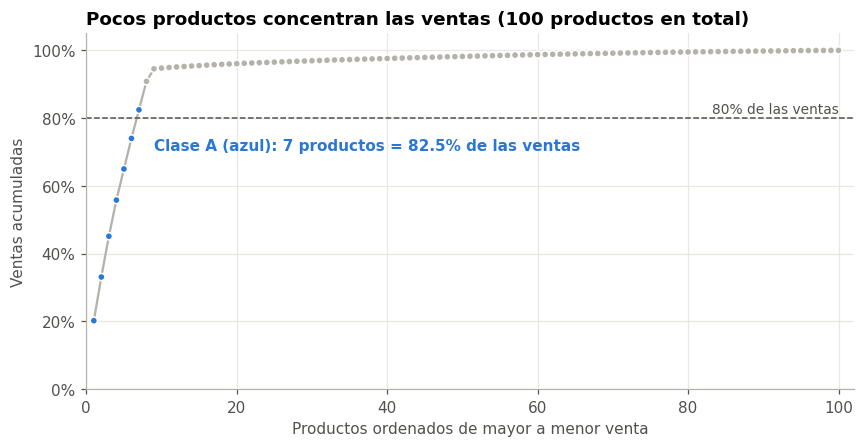

In [6]:
clase_a = abc.index[abc["clase"] == "A"].tolist()

fig, ax = plt.subplots(figsize=(9, 4.2))
x = range(1, len(abc) + 1)
colores = [AZUL if c == "A" else GRIS for c in abc["clase"]]
ax.plot(x, abc["pct_acumulado"], color=GRIS, linewidth=1.5, zorder=1)
ax.scatter(x, abc["pct_acumulado"], c=colores, s=22, zorder=2, edgecolors="white", linewidths=1)
ax.axhline(80, color=TEXTO_2, linewidth=1, linestyle="--")
ax.text(len(abc), 81.5, "80% de las ventas", ha="right", color=TEXTO_2, fontsize=9)
n_a, pct_a = len(clase_a), abc.loc[clase_a, "pct"].sum()
ax.text(n_a + 2, abc["pct_acumulado"].iloc[n_a - 1] - 12,
        f"Clase A (azul): {n_a} productos = {pct_a:.1f}% de las ventas",
        color=AZUL, fontweight="bold")
ax.set_title(f"Pocos productos concentran las ventas ({len(abc)} productos en total)")
ax.set_xlabel("Productos ordenados de mayor a menor venta")
ax.set_ylabel("Ventas acumuladas")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 105)
ax.set_xlim(0, len(abc) + 2)
fig.savefig("figuras/01_pareto_abc.png")
plt.show()

## 3. Demanda mensual de los productos clase A

Para planear inventario cuento **unidades**, no dinero. El **coeficiente de variación (CV)** = desviación estándar / promedio mide qué tan estable es la demanda: abajo de 10% es muy estable.

In [7]:
demanda = (datos[datos["Product Name"].isin(clase_a)]
           .pivot_table(index=datos["fecha"].dt.to_period("M"), columns="Product Name",
                        values="Order Item Quantity", aggfunc="sum")
           .fillna(0)[clase_a])

perfil = pd.DataFrame({
    "promedio_mes": demanda.mean(),
    "desv_est": demanda.std(),
    "minimo": demanda.min(),
    "maximo": demanda.max(),
})
perfil["cv_%"] = perfil["desv_est"] / perfil["promedio_mes"] * 100
perfil

,promedio_mes,desv_est,minimo,maximo,cv_%
Product Name,,,,,
Field & Stream Sportsman 16 Gun Fire Safe,502.4,23.0,426,541,4.6
Perfect Fitness Perfect Rip Deck,"2,135.0",118.6,1822,2332,5.6
Diamondback Women's Serene Classic Comfort Bi,398.2,17.2,370,433,4.3
Nike Men's Free 5.0+ Running Shoe,"1,061.1",86.7,894,1298,8.2
Nike Men's Dri-FIT Victory Golf Polo,"1,822.8",103.9,1643,2096,5.7
Pelican Sunstream 100 Kayak,448.9,26.1,393,498,5.8
O'Brien Men's Neoprene Life Vest,"1,674.7",103.6,1487,1905,6.2


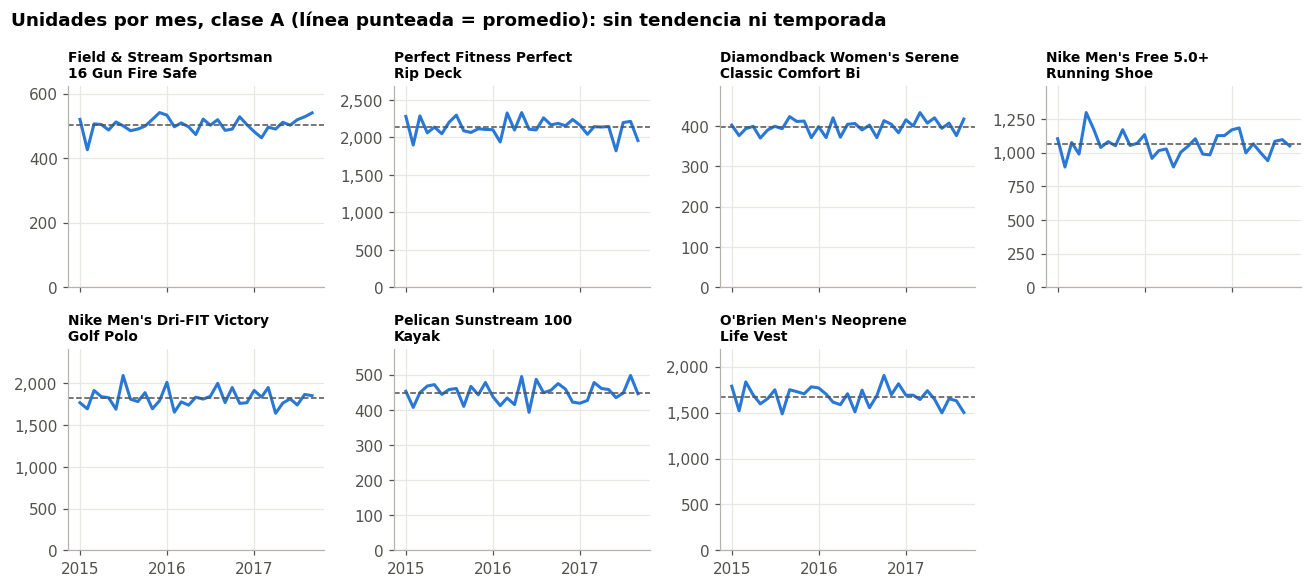

In [8]:
fig, ejes = plt.subplots(2, 4, figsize=(12, 5.4), sharex=True)
fechas = demanda.index.to_timestamp()
for ax, producto in zip(ejes.flat, clase_a):
    serie = demanda[producto]
    ax.plot(fechas, serie, color=AZUL)
    ax.axhline(serie.mean(), color=TEXTO_2, linewidth=1, linestyle="--")
    ax.set_title(textwrap.fill(producto, 26), fontsize=9)
    ax.set_ylim(0, serie.max() * 1.15)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in ejes.flat[len(clase_a):]:
    ax.remove()
fig.suptitle("Unidades por mes, clase A (línea punteada = promedio): sin tendencia ni temporada",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
fig.savefig("figuras/02_demanda_clase_a.png")
plt.show()

## 4. ¿Qué método de pronóstico funciona mejor?

Comparo cinco métodos simples con una **prueba retrospectiva (backtest)**: para cada mes de enero a septiembre de 2017 pronostico usando solo los meses anteriores y comparo contra lo que se vendió de verdad.

| Método | Pronóstico del mes siguiente |
|---|---|
| Ingenuo | Lo que se vendió el mes pasado |
| Promedio móvil 3 | Promedio de los últimos 3 meses |
| Promedio móvil 6 | Promedio de los últimos 6 meses |
| Estacional ingenuo | Lo que se vendió el mismo mes del año anterior |
| Promedio histórico | Promedio de todos los meses anteriores |

Error: **WAPE** = suma de errores absolutos / suma de la demanda real. Se lee como "me equivoco X% de las unidades".

In [9]:
metodos = {
    "Ingenuo": demanda.shift(1),
    "Promedio móvil 3": demanda.rolling(3).mean().shift(1),
    "Promedio móvil 6": demanda.rolling(6).mean().shift(1),
    "Estacional ingenuo": demanda.shift(12),
    "Promedio histórico": demanda.expanding().mean().shift(1),
}
prueba = demanda.index >= pd.Period("2017-01", "M")

def wape(real, pronostico):
    return (real - pronostico).abs().sum() / real.sum() * 100

errores = pd.DataFrame({
    nombre: [wape(demanda.loc[prueba, p], pron.loc[prueba, p]) for p in clase_a]
    for nombre, pron in metodos.items()
}, index=clase_a)

total = pd.Series({nombre: wape(demanda[prueba].stack(), pron[prueba].stack())
                   for nombre, pron in metodos.items()}).sort_values()
mejor = total.index[0]
print(f"Mejor método: {mejor} ({total.iloc[0]:.1f}% WAPE)")
print(f"Productos donde gana: {(errores.idxmin(axis=1) == mejor).sum()} de {len(clase_a)}")
total.to_frame("WAPE_%")

Mejor método: Promedio histórico (4.3% WAPE)
Productos donde gana: 5 de 7


,WAPE_%
Promedio histórico,4.3
Promedio móvil 6,4.8
Promedio móvil 3,5.0
Estacional ingenuo,5.8
Ingenuo,6.1


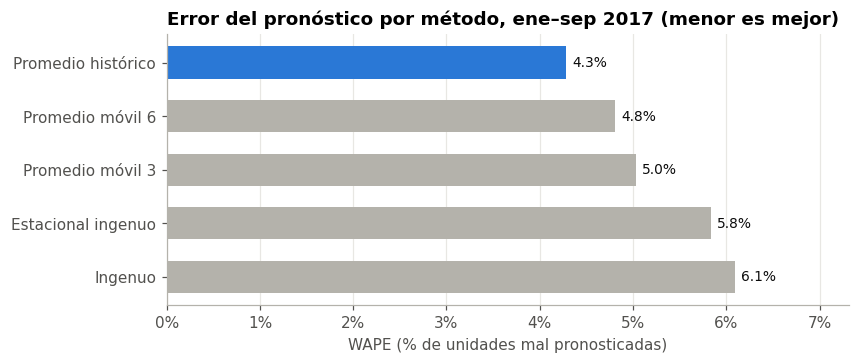

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
orden = total.sort_values(ascending=True)
colores = [AZUL if m == mejor else GRIS for m in orden.index][::-1]
barras = ax.barh(orden.index[::-1], orden.values[::-1], color=colores, height=0.6)
ax.bar_label(barras, fmt="%.1f%%", padding=4, color=TEXTO, fontsize=9)
ax.set_title("Error del pronóstico por método, ene–sep 2017 (menor es mejor)")
ax.set_xlabel("WAPE (% de unidades mal pronosticadas)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.set_xlim(0, orden.max() * 1.2)
fig.savefig("figuras/03_error_pronostico.png")
plt.show()

**¿Por qué gana el promedio?** Cuando la demanda no tiene tendencia ni temporada, la diferencia entre un mes y otro es casi puro ruido. Los métodos que reaccionan al último mes (ingenuo, promedio móvil corto) copian ese ruido; el estacional ingenuo pierde porque no hay temporada que aprovechar. La gráfica de abajo lo muestra con el producto de mayor demanda en unidades.

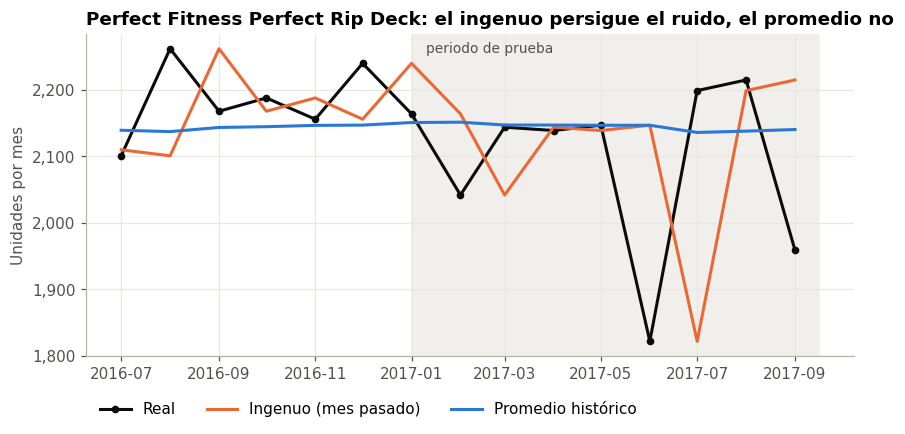

In [11]:
producto = perfil["promedio_mes"].idxmax()
ventana = demanda.index >= pd.Period("2016-07", "M")
fig, ax = plt.subplots(figsize=(9, 3.8))
f = demanda.index[ventana].to_timestamp()
ax.plot(f, demanda.loc[ventana, producto], color=TEXTO, label="Real", marker="o", markersize=4)
ax.plot(f, metodos["Ingenuo"].loc[ventana, producto], color=NARANJA, label="Ingenuo (mes pasado)")
ax.plot(f, metodos[mejor].loc[ventana, producto], color=AZUL, label=mejor)
ax.axvspan(pd.Timestamp("2017-01-01"), f.max() + pd.Timedelta(days=15), color="#f0efec", zorder=0)
ax.text(pd.Timestamp("2017-01-10"), ax.get_ylim()[1] * 0.995, "periodo de prueba", va="top", color=TEXTO_2, fontsize=9)
ax.set_title(f"{producto}: el ingenuo persigue el ruido, el promedio no")
ax.set_ylabel("Unidades por mes")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.1), ncols=3)
fig.savefig("figuras/04_real_vs_pronostico.png")
plt.show()

## 5. Stock de seguridad y punto de reorden

Con demanda estable conviene un sistema de **revisión continua**: cuando el inventario baja a cierto nivel (el punto de reorden) se pide de nuevo.

- **Stock de seguridad (SS)** = z × σ<sub>d</sub> × √LT
- **Punto de reorden (ROP)** = demanda diaria promedio × LT + SS

donde σ<sub>d</sub> es la desviación estándar de la demanda diaria, LT es el tiempo de entrega del proveedor en días y z sale del nivel de servicio (95% → z = 1.645).

**Supuesto:** el dataset no trae el tiempo de entrega de los proveedores. Uso **LT = 7 días** como caso base y abajo muestro cómo cambia el resultado con 14 y 30 días.

In [12]:
NIVEL_SERVICIO, LT = 0.95, 7
z = NormalDist().inv_cdf(NIVEL_SERVICIO)

# Demanda diaria; los días sin ventas cuentan como 0
dias = pd.date_range("2015-01-01", "2017-09-30", freq="D")
diaria = (datos[datos["Product Name"].isin(clase_a)]
          .pivot_table(index=datos["fecha"].dt.normalize(), columns="Product Name",
                       values="Order Item Quantity", aggfunc="sum")
          .reindex(dias, fill_value=0).fillna(0)[clase_a])
precio = datos.groupby("Product Name")["Product Price"].median()

inventario = pd.DataFrame({"demanda_dia": diaria.mean(), "desv_dia": diaria.std(), "precio": precio[clase_a]})
inventario["stock_seguridad"] = (z * inventario["desv_dia"] * LT ** 0.5).round()
inventario["punto_reorden"] = (inventario["demanda_dia"] * LT + inventario["stock_seguridad"]).round()
inventario["valor_ss"] = inventario["stock_seguridad"] * inventario["precio"]
inventario["ss_en_dias"] = inventario["stock_seguridad"] / inventario["demanda_dia"]

print(f"z = {z:.3f}  |  LT = {LT} días  |  Días sin venta de algún producto A: {(diaria == 0).any(axis=1).sum()}")
inventario.sort_values("valor_ss", ascending=False)

z = 1.645  |  LT = 7 días  |  Días sin venta de algún producto A: 0


,demanda_dia,desv_dia,precio,stock_seguridad,punto_reorden,valor_ss,ss_en_dias
Product Name,,,,,,,
Field & Stream Sportsman 16 Gun Fire Safe,16.5,4.2,400.0,18.0,134.0,"7,199.6",1.1
Nike Men's Free 5.0+ Running Shoe,34.9,11.8,100.0,51.0,295.0,"5,099.5",1.5
Diamondback Women's Serene Classic Comfort Bi,13.1,3.6,300.0,16.0,108.0,"4,799.7",1.2
Perfect Fitness Perfect Rip Deck,70.2,16.3,60.0,71.0,562.0,"4,259.3",1.0
Nike Men's Dri-FIT Victory Golf Polo,59.9,15.6,50.0,68.0,487.0,"3,400.0",1.1
Pelican Sunstream 100 Kayak,14.8,4.0,200.0,17.0,120.0,"3,399.8",1.2
O'Brien Men's Neoprene Life Vest,55.0,14.5,50.0,63.0,448.0,"3,148.7",1.1


In [13]:
print(f"Stock de seguridad total clase A: {inventario['stock_seguridad'].sum():,.0f} unidades "
      f"= ${inventario['valor_ss'].sum():,.0f} a precio de venta")

Stock de seguridad total clase A: 304 unidades = $31,307 a precio de venta


**Sensibilidad.** ¿Cuánto dinero en stock de seguridad necesito según el nivel de servicio y el tiempo de entrega? Cada celda es el valor total del stock de seguridad de los 8 productos clase A.

In [14]:
def valor_ss(nivel, lt):
    z = NormalDist().inv_cdf(nivel)
    return (z * inventario["desv_dia"] * lt ** 0.5).round().mul(inventario["precio"]).sum()

niveles, tiempos = [0.90, 0.95, 0.99], [7, 14, 30]
sensibilidad = pd.DataFrame({f"LT {lt} días": [valor_ss(n, lt) for n in niveles] for lt in tiempos},
                            index=[f"{n:.0%}" for n in niveles])
sensibilidad.index.name = "nivel de servicio"
sensibilidad.style.format("${:,.0f}")

,LT 7 días,LT 14 días,LT 30 días
nivel de servicio,,,
90%,"$24,397","$34,526","$50,495"
95%,"$31,307","$44,605","$64,913"
99%,"$44,605","$62,963","$91,870"


In [15]:
subir_99 = valor_ss(0.99, LT) / valor_ss(0.95, LT) - 1
lt_mes = valor_ss(0.95, 30) / valor_ss(0.95, 7) - 1
print(f"Pasar de 95% a 99% de servicio sube el stock de seguridad {subir_99:.0%}")
print(f"Pasar de 7 a 30 días de tiempo de entrega lo sube {lt_mes:.0%}")

Pasar de 95% a 99% de servicio sube el stock de seguridad 42%
Pasar de 7 a 30 días de tiempo de entrega lo sube 107%


## 6. Conclusiones

| # | Hallazgo | Resultado |
|---|---|---|
| 1 | Concentración | **7 productos (7%)** generan **82.5%** de las ventas |
| 2 | Estabilidad | La demanda mensual de la clase A varía solo **4% a 8%** (CV), sin tendencia ni temporada |
| 3 | Pronóstico | El **promedio histórico** tiene el menor error (**4.3%** WAPE) contra 6.1% del ingenuo, y gana en 5 de 7 productos |
| 4 | Stock de seguridad | Con 95% de servicio y 7 días de entrega bastan **304 unidades (~$31,000)**: de 1 a 1.5 días de demanda por producto |
| 5 | Lo que más pesa | Que el proveedor tarde 30 días en vez de 7 **duplica** el stock de seguridad (+107%); subir el servicio de 95% a 99% lo sube 42% |

**Recomendaciones**

1. **Revisión continua para los 7 productos A** usando los puntos de reorden de la tabla de la sección 5. Los productos B y C pueden ir con revisión periódica.
2. **Pronosticar con el promedio histórico** y medir el error cada mes. Un modelo más complejo no se justifica con demanda tan estable; si el error pasa de ~10%, revisar si cambió el patrón.
3. **Medir y negociar el tiempo de entrega de los proveedores** antes que subir el nivel de servicio. Es la variable que más mueve el inventario y hoy no se registra.

**Limitaciones**

- El tiempo de entrega de 7 días es un supuesto: el dataset no trae datos de proveedores.
- El stock de seguridad solo considera la variación de la demanda, no la variación del tiempo de entrega.
- El valor del inventario está a precio de venta porque el dataset no trae el costo; a costo sería menor.
- La demanda es más estable de lo normal en datos reales, lo que sugiere que el dataset es en parte simulado.